# 02 · A/B test: first gate at level 30 or 40

**Question.** Does moving the first gate from level 30 to level 40 change retention?
**Answer.** Yes for D7: 19.02% with the gate at level 30 against 18.20% at level 40 (p = 0.0016, bootstrap interval excludes 0). D1 is inconclusive. **Recommendation: keep the gate at level 30.**
**Method.** Sample ratio check, two-proportion z-test, Wilson intervals, bootstrap of the difference (5,000 resamples, seed 42). Two indicators are tested, so the threshold is 0.025 (Bonferroni). Code: `game_players.ab_test`.

In [1]:
import matplotlib.pyplot as plt

from game_players import ab_test, config
from game_players.database import connect

con = connect()
players = con.execute("SELECT version, retention_1, retention_7 FROM cookie_cats").df()
con.close()

## 1. Sample ratio

In [2]:
sizes = players["version"].value_counts().sort_index()
print(sizes.to_string())
print(f"Sample ratio mismatch, p-value: {ab_test.srm_pvalue(sizes):.4f}")

version
gate_30    44700
gate_40    45489
Sample ratio mismatch, p-value: 0.0086


The groups differ by 789 players (p = 0.009): the split is slightly unbalanced. Not enough to reject the test, but the assignment should be checked before a production decision.

## 2. Retention by group, 95% Wilson intervals

In [3]:
(ab_test.retention_by_version(players)
 .style.format({"retention": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}"}).hide(axis="index"))

indicator,version,players,retention,ci_low,ci_high
Day 1,gate_30,44700,44.82%,44.36%,45.28%
Day 7,gate_30,44700,19.02%,18.66%,19.39%
Day 1,gate_40,45489,44.23%,43.77%,44.69%
Day 7,gate_40,45489,18.20%,17.85%,18.56%


## 3. Test of the difference gate_40 − gate_30

In [4]:
results = ab_test.compare_retention(players)
results.style.format(precision=4).hide(axis="index")

indicator,retention_gate_30,retention_gate_40,difference_points,p_value,boot_ci95_low_points,boot_ci95_high_points,boot_ci975_low_points,boot_ci975_high_points,conclusion
Day 1,0.4482,0.4423,-0.5905,0.0744,-1.2217,0.0566,-1.3042,0.1399,Inconclusive
Day 7,0.1902,0.1820,-0.8201,0.0016,-1.3278,-0.3226,-1.4058,-0.2453,gate_40 retains less (significant)


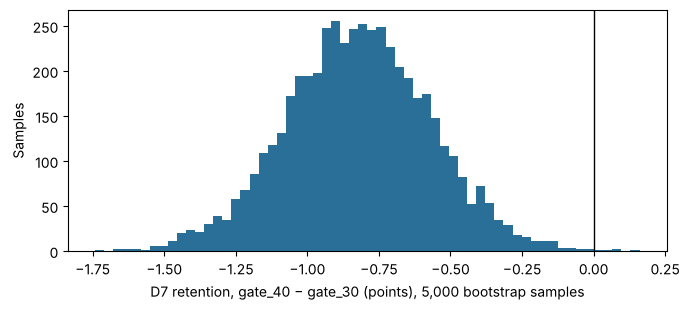

In [5]:
diffs = 100 * ab_test.bootstrap_diff(players.loc[players.version == "gate_30", "retention_7"].astype(int).values,
                                     players.loc[players.version == "gate_40", "retention_7"].astype(int).values)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(diffs, bins=60, color="#2a6f97")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("D7 retention, gate_40 − gate_30 (points), 5,000 bootstrap samples")
ax.set_ylabel("Samples")
plt.tight_layout()
plt.show()

## Conclusion

**Day 7.** Retention is 19.02% with gate_30 against 18.20% with gate_40 (−0.8 point). The difference is significant (p = 0.0016 < 0.025) and the bootstrap intervals exclude 0.

**Day 1.** The difference is not significant (p = 0.074): no conclusion. "Inconclusive" does not mean "no effect".

**Recommendation.** Keep the gate at level 30.

**Limits.** Retention is not revenue, and this dataset contains no revenue. The long-term effect is unknown. The groups differ slightly in size (p = 0.009).